# E3 — LSTM and GRU for Fashion-MNIST image sequences

This notebook contains the complete experiment: data preparation, model definitions, explicit training loops, evaluation and sequence-order analysis. It runs independently of the other exercise notebooks and project Python files. AI assistance is disclosed in [AI_USE_REPORT.md](../AI_USE_REPORT.md).

We compare LSTM and GRU on two image representations, with MLP and CNN baselines trained here from scratch. All six models use the same 54,000 training images, 6,000 validation images and 10,000 held-out test images. Each configuration runs for 30 epochs with seeds 42, 43 and 44. This is **18 complete training runs**, followed by test evaluation of the selected checkpoints.

## 1. Libraries and experimental settings

The only dependencies are standard Python libraries, PyTorch, torchvision, NumPy, pandas, Matplotlib and scikit-learn. The installation cell is useful in a fresh notebook environment. All code required for the experiment appears below.

In [1]:
%pip install -q torch torchvision numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from contextlib import nullcontext
from datetime import datetime, timezone
from pathlib import Path
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.datasets import FashionMNIST as TorchFashionMNIST
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

DATA_DIR = Path("data")
RUN_DIR = Path("runs") / "E3" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=False)
SEEDS = (42, 43, 44)
SPLIT_SEED = 2026
EPOCHS = 30
BATCH_SIZE = 256
NUM_WORKERS = 0
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
CLIP_NORM = 1.0
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
EXPERIMENTS = [
    {"id": "e3_mlp", "model": "mlp", "tokenizer": "none"},
    {"id": "e3_cnn", "model": "cnn", "tokenizer": "none"},
    {"id": "e3_lstm_rows", "model": "lstm", "tokenizer": "rows"},
    {"id": "e3_gru_rows", "model": "gru", "tokenizer": "rows"},
    {"id": "e3_lstm_patches", "model": "lstm", "tokenizer": "patches"},
    {"id": "e3_gru_patches", "model": "gru", "tokenizer": "patches"},
]


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def choose_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


device = choose_device()
# Keep all six configurations in FP32, including CUDA matrix multiplication.
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
print(f"Device: {device}; PyTorch: {torch.__version__}; outputs: {RUN_DIR}")

Device: cuda; PyTorch: 2.10.0+cu130; outputs: runs/E3/20261107T164828617407Z


## 2. Data preparation and exploration

Fashion-MNIST contains 28×28 grayscale images from ten clothing categories. The split uses `train_test_split` with class stratification and random_state=2026, then sorts the selected indices. Each class contributes 600 validation images. This leaves 5,400 training images per class. The mean and standard deviation are computed from **training pixels only** and applied unchanged to validation and test images. Test images are loaded only after every training run has finished.

Source: [Zalando Research Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist). The original images and labels are distributed as gzip-compressed IDX files.

In [3]:
class FashionMNIST(TorchFashionMNIST):
    # Use the dataset author's HTTPS mirror, retaining torchvision's checksums.
    mirrors = [
        "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
        *TorchFashionMNIST.mirrors,
    ]


base_train = FashionMNIST(str(DATA_DIR), train=True, download=True)
labels = base_train.targets.numpy()
train_indices, validation_indices = train_test_split(
    np.arange(len(labels)), test_size=6000, random_state=SPLIT_SEED, stratify=labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
assert len(train_indices) == 54000 and len(validation_indices) == 6000
assert not np.intersect1d(train_indices, validation_indices).size

pixel_sum, pixel_square_sum, pixel_count = 0.0, 0.0, 0
for start in range(0, len(train_indices), 2048):
    images = base_train.data[torch.as_tensor(train_indices[start:start + 2048])].double() / 255
    pixel_sum += images.sum().item()
    pixel_square_sum += images.square().sum().item()
    pixel_count += images.numel()
MEAN = pixel_sum / pixel_count
STD = (pixel_square_sum / pixel_count - MEAN ** 2) ** 0.5
assert STD > 0


class NormalizedImages(Dataset):
    def __init__(self, images, targets, indices):
        self.images = images
        self.targets = targets
        self.indices = np.asarray(indices, dtype=np.int64)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        original_index = int(self.indices[index])
        image = self.images[original_index].unsqueeze(0).float() / 255
        image = (image - MEAN) / STD
        return image, int(self.targets[original_index]), original_index


train_set = NormalizedImages(base_train.data, base_train.targets, train_indices)
validation_set = NormalizedImages(base_train.data, base_train.targets, validation_indices)
np.savez_compressed(RUN_DIR / "split_indices.npz", train=train_indices, validation=validation_indices)
print(f"Train: {len(train_set):,}; validation: {len(validation_set):,}; mean={MEAN:.6f}; std={STD:.6f}")

Train: 54,000; validation: 6,000; mean=0.285829; std=0.352922


,mean,std,minimum,maximum
"Raw pixels [0, 1]",2.858291e-01,0.352922,0.000000,1.000000
Normalized pixels,-2.509684e-08,1.000000,-0.809892,2.023592


,class,training,validation
0,T-shirt/top,5400,600
1,Trouser,5400,600
2,Pullover,5400,600
3,Dress,5400,600
4,Coat,5400,600
5,Sandal,5400,600
6,Shirt,5400,600
7,Sneaker,5400,600
8,Bag,5400,600
9,Ankle boot,5400,600


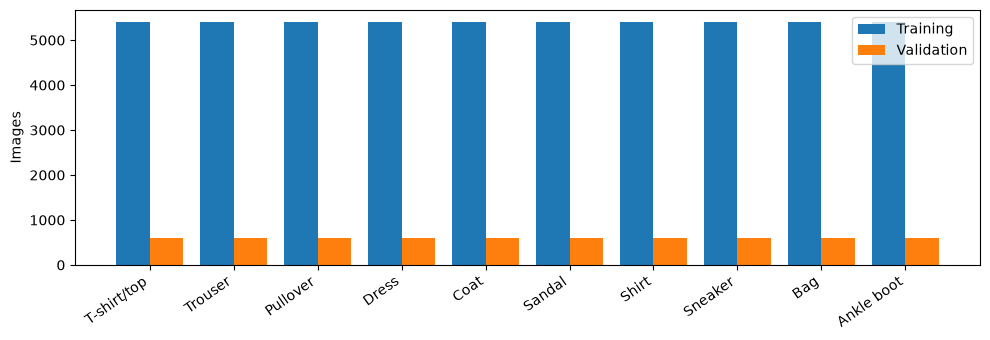

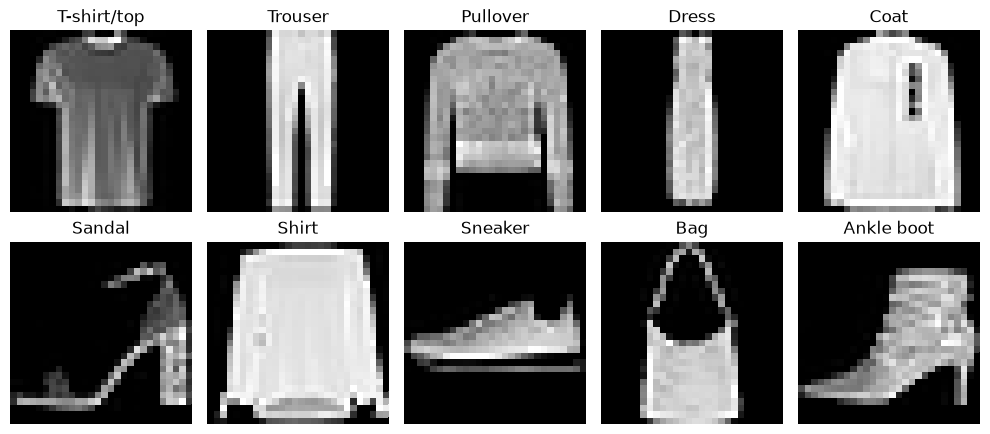

In [4]:
# Report training pixel statistics before and after normalization.
training_pixels = base_train.data[torch.as_tensor(train_indices)].float() / 255
raw_statistics = [training_pixels.mean().item(), training_pixels.std(correction=0).item(),
                  training_pixels.min().item(), training_pixels.max().item()]
training_pixels.sub_(MEAN).div_(STD)
normalized_statistics = [training_pixels.mean().item(), training_pixels.std(correction=0).item(),
                         training_pixels.min().item(), training_pixels.max().item()]
pixel_statistics = pd.DataFrame(
    [raw_statistics, normalized_statistics], columns=["mean", "std", "minimum", "maximum"],
    index=["Raw pixels [0, 1]", "Normalized pixels"],
)
display(pixel_statistics)
pixel_statistics.to_csv(RUN_DIR / "training_pixel_statistics.csv", index=False)
del training_pixels

class_counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "training": np.bincount(labels[train_indices], minlength=10),
    "validation": np.bincount(labels[validation_indices], minlength=10),
})
display(class_counts)
fig, ax = plt.subplots(figsize=(10, 3.5))
x = np.arange(10)
ax.bar(x - .2, class_counts["training"], .4, label="Training")
ax.bar(x + .2, class_counts["validation"], .4, label="Validation")
ax.set_xticks(x, CLASS_NAMES, rotation=35, ha="right")
ax.set_ylabel("Images")
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "class_distribution.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
rng = np.random.default_rng(SPLIT_SEED)
for class_id, ax in enumerate(axes.flat):
    index = rng.choice(train_indices[labels[train_indices] == class_id])
    ax.imshow(base_train.data[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "training_examples.png", dpi=150)
plt.show()

## 3. Image sequences and model definitions

**Rows:** each image becomes 28 tokens with 28 pixel values per token. Rows are read from top to bottom, with pixels ordered left to right.

**4×4 patches:** each image becomes 49 non-overlapping tokens with 16 values per token. Patches are read left to right, then top to bottom; pixels within a patch follow the same order.

For either representation, a single recurrent layer maps tokens to hidden states of dimension 128. A dropout layer with probability 0.1 and a linear layer classify the **last hidden state**. Both initial hidden states and LSTM cell states are zero. The recurrent biases are initialized to zero, matching the exercise's baseline setup. `nn.LSTM` and `nn.GRU` are explicitly allowed by the E3 exercise.

LSTM uses input, forget and output gates:

\[
i_t=\sigma(W_i x_t+U_i h_{t-1}+b_i),\quad
f_t=\sigma(W_f x_t+U_f h_{t-1}+b_f),\quad
o_t=\sigma(W_o x_t+U_o h_{t-1}+b_o),
\]
\[
c_t=f_t\odot c_{t-1}+i_t\odot\tanh(W_g x_t+U_g h_{t-1}+b_g),\quad
h_t=o_t\odot\tanh(c_t).
\]

GRU uses reset and update gates. PyTorch applies the reset gate to the hidden affine transformation in its candidate state:

\[
r_t=\sigma(W_r x_t+U_r h_{t-1}+b_r),\quad
z_t=\sigma(W_z x_t+U_z h_{t-1}+b_z),
\]
\[
n_t=\tanh(W_nx_t+b_{in}+r_t\odot(U_nh_{t-1}+b_{hn})),\quad
h_t=(1-z_t)\odot n_t+z_t\odot h_{t-1}.
\]

The MLP is 784→256→128→10 with ReLU and dropout 0.2. The CNN has two convolution–batch normalization–ReLU–pooling blocks (32 and 64 channels), then a 128-unit classifier with dropout 0.2. These E1 architectures are defined and trained independently in this notebook.

In [5]:
def image_sequence(images, tokenizer):
    if tokenizer == "rows":
        return images[:, 0, :, :]                 # [B, 28, 28]
    if tokenizer == "patches":
        return F.unfold(images, kernel_size=4, stride=4).transpose(1, 2)  # [B, 49, 16]
    raise ValueError(f"Unknown tokenizer: {tokenizer}")


class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Dropout(.2),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(.2), nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.classifier(images)


class CNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(.2),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


class RecurrentClassifier(nn.Module):
    def __init__(self, kind, tokenizer):
        super().__init__()
        self.tokenizer = tokenizer
        input_size = 28 if tokenizer == "rows" else 16
        recurrent_layer = {"lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = recurrent_layer(input_size, 128, num_layers=1, batch_first=True)
        nn.init.zeros_(self.rnn.bias_ih_l0)
        nn.init.zeros_(self.rnn.bias_hh_l0)
        self.readout = nn.Sequential(nn.Dropout(.1), nn.Linear(128, 10))

    def forward_sequence(self, sequence):
        outputs, _ = self.rnn(sequence)
        return self.readout(outputs[:, -1])

    def forward(self, images):
        return self.forward_sequence(image_sequence(images, self.tokenizer))


def build_model(experiment):
    if experiment["model"] == "mlp":
        return MLPClassifier()
    if experiment["model"] == "cnn":
        return CNNClassifier()
    return RecurrentClassifier(experiment["model"], experiment["tokenizer"])


# Pure tensor checks show shapes and verify the spatial ordering without loading a batch.
example = torch.arange(784, dtype=torch.float32).reshape(1, 1, 28, 28)
assert image_sequence(example, "rows").shape == (1, 28, 28)
patches = image_sequence(example, "patches")
assert patches.shape == (1, 49, 16)
assert torch.equal(patches[0, 0], example[0, 0, :4, :4].flatten())
assert torch.equal(patches[0, 1], example[0, 0, :4, 4:8].flatten())
shape_rows = []
for experiment in EXPERIMENTS:
    seed_everything(SEEDS[0])
    model = build_model(experiment).eval()
    with torch.no_grad():
        output = model(torch.zeros(2, 1, 28, 28))
    assert output.shape == (2, 10)
    shape_rows.append({**experiment, "n_parameters": sum(p.numel() for p in model.parameters())})
display(pd.DataFrame(shape_rows))
del model

# MPS support can vary by PyTorch version: fail visibly before the long experiment
# if a required recurrent forward/backward operation is unavailable on this device.
if device.type == "mps":
    for kind in ("lstm", "gru"):
        model = RecurrentClassifier(kind, "patches").to(device)
        synthetic_images = torch.randn(2, 1, 28, 28, device=device)
        model(synthetic_images).square().mean().backward()
    del model, synthetic_images
    torch.mps.synchronize()
seed_everything(SEEDS[0])

,id,model,tokenizer,n_parameters
0,e3_mlp,mlp,none,235146
1,e3_cnn,cnn,none,421738
2,e3_lstm_rows,lstm,rows,82186
3,e3_gru_rows,gru,rows,61962
4,e3_lstm_patches,lstm,patches,76042
5,e3_gru_patches,gru,patches,57354


## 4. Explicit training and validation loops

Every model uses AdamW (learning rate 0.001, weight decay 0.0001), batch size 256, FP32 and gradient clipping at norm 1.0. A cosine schedule reduces the learning rate to 1% of its initial value over 30 epochs. The objective is cross-entropy on logits. No augmentation is applied.

Training uses `zero_grad → forward → cross-entropy → backward → clip → step`. Validation runs with dropout disabled and does not update weights. We save the checkpoint with the highest validation accuracy; ties are broken by lower validation cross-entropy. The training time below covers training batches; `seconds_per_epoch` is the median training time excluding the first epoch. Peak allocated memory is measured only on CUDA and is missing for other devices. Timing comparisons apply to this device and execution environment.

In [6]:
def make_loader(dataset, shuffle=False, seed=9017):
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
        generator=torch.Generator().manual_seed(seed), num_workers=NUM_WORKERS,
        pin_memory=device.type == "cuda", drop_last=False,
    )


def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, count = 0.0, 0, 0
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    synchronize()
    start = time.perf_counter()
    for images, targets, _ in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, targets)
        if not torch.isfinite(loss):
            raise FloatingPointError("Training loss is not finite.")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM, error_if_nonfinite=True)
        optimizer.step()
        count += targets.numel()
        total_loss += loss.item() * targets.numel()
        correct += (logits.detach().argmax(1) == targets).sum().item()
    synchronize()
    seconds = time.perf_counter() - start
    peak = torch.cuda.max_memory_allocated(device) / 2**20 if device.type == "cuda" else None
    return total_loss / count, correct / count, seconds, peak


@torch.inference_mode()
def evaluate(model, loader, collect_predictions=False):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    predictions = []
    for images, targets, indices in loader:
        images, targets = images.to(device), targets.to(device)
        logits = model(images)
        total_loss += F.cross_entropy(logits, targets, reduction="sum").item()
        predicted = logits.argmax(1)
        correct += (predicted == targets).sum().item()
        count += targets.numel()
        if collect_predictions:
            confidence = logits.softmax(1).max(1).values
            predictions.extend(zip(indices.tolist(), targets.cpu().tolist(),
                                   predicted.cpu().tolist(), confidence.cpu().tolist()))
    return total_loss / count, correct / count, predictions


def train_model(experiment, seed):
    seed_everything(seed)
    directory = RUN_DIR / experiment["id"] / f"seed_{seed}"
    directory.mkdir(parents=True, exist_ok=False)
    model = build_model(experiment).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * .01,
    )
    train_loader = make_loader(train_set, shuffle=True, seed=seed)
    validation_loader = make_loader(validation_set)
    best_accuracy, best_ce, best_epoch = -1.0, float("inf"), 0
    history = []
    for epoch in range(1, EPOCHS + 1):
        learning_rate = optimizer.param_groups[0]["lr"]
        train_ce, train_accuracy, seconds, peak = train_epoch(model, train_loader, optimizer)
        validation_ce, validation_accuracy, _ = evaluate(model, validation_loader)
        history.append({
            "epoch": epoch, "learning_rate": learning_rate,
            "train_ce": train_ce, "train_accuracy": train_accuracy,
            "validation_ce": validation_ce, "validation_accuracy": validation_accuracy,
            "train_seconds": seconds, "peak_memory_mib": peak,
        })
        if (validation_accuracy > best_accuracy or
                (validation_accuracy == best_accuracy and validation_ce < best_ce)):
            best_accuracy, best_ce, best_epoch = validation_accuracy, validation_ce, epoch
            torch.save({name: value.detach().cpu().clone() for name, value in model.state_dict().items()},
                       directory / "best.pt")
        scheduler.step()
        pd.DataFrame(history).to_csv(directory / "history.csv", index=False)
        print(f"{experiment['id']} seed={seed} epoch={epoch:02d}/{EPOCHS} "
              f"train CE={train_ce:.4f} val acc={validation_accuracy:.4%} ({seconds:.1f}s)", flush=True)
    history_frame = pd.DataFrame(history)
    row = {
        **experiment, "seed": seed, "val_accuracy": best_accuracy,
        "n_parameters": sum(p.numel() for p in model.parameters()),
        "train_seconds": history_frame["train_seconds"].sum(),
        "seconds_per_epoch": history_frame["train_seconds"].iloc[1:].median(),
        "peak_memory_mib": history_frame["peak_memory_mib"].max() if device.type == "cuda" else None,
        "best_epoch": best_epoch,
    }
    del model, optimizer, scheduler
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return row

In [7]:
settings = {
    "dataset": "Fashion-MNIST", "train_size": 54000, "validation_size": 6000, "test_size": 10000,
    "split_seed": SPLIT_SEED, "mean": MEAN, "std": STD,
    "seeds": list(SEEDS), "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "optimizer": "AdamW", "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
    "clip_norm": CLIP_NORM, "scheduler": "CosineAnnealingLR", "minimum_lr": LEARNING_RATE * .01,
    "dtype": "float32", "num_workers": NUM_WORKERS, "device": str(device),
    "device_name": torch.cuda.get_device_name(device) if device.type == "cuda" else str(device),
    "torch_version": torch.__version__, "experiments": EXPERIMENTS,
    "recurrent_hidden_size": 128, "recurrent_layers": 1, "recurrent_dropout": .1,
    "recurrent_readout": "last hidden state", "checkpoint_selection": "validation accuracy, then lower CE",
}
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
training_rows = []
for experiment in EXPERIMENTS:
    for seed in SEEDS:
        training_rows.append(train_model(experiment, seed))
        pd.DataFrame(training_rows).to_csv(RUN_DIR / "training_results.csv", index=False)
assert len(training_rows) == 18
print("All 18 models have completed training. Checkpoint selection is finished.")

e3_mlp seed=42 epoch=01/30 train CE=0.5932 val acc=85.6333% (1.1s)


e3_mlp seed=42 epoch=02/30 train CE=0.3971 val acc=86.4333% (0.9s)


e3_mlp seed=42 epoch=03/30 train CE=0.3550 val acc=86.6167% (0.9s)


e3_mlp seed=42 epoch=04/30 train CE=0.3330 val acc=87.8333% (0.9s)


e3_mlp seed=42 epoch=05/30 train CE=0.3147 val acc=88.0000% (0.9s)


e3_mlp seed=42 epoch=06/30 train CE=0.2975 val acc=88.5500% (0.8s)


... (531 outputs left out)

e3_gru_patches seed=44 epoch=28/30 train CE=0.2447 val acc=89.0333% (1.1s)


e3_gru_patches seed=44 epoch=29/30 train CE=0.2438 val acc=88.9833% (1.1s)


e3_gru_patches seed=44 epoch=30/30 train CE=0.2428 val acc=88.9833% (1.1s)


All 18 models have completed training. Checkpoint selection is finished.


## 5. Learning curves

The following curves use seed 42 for every configuration, chosen before evaluation. They show one run per model, not a mean over seeds. Compare training and validation accuracy and cross-entropy to assess optimization and possible overfitting before opening the test set.

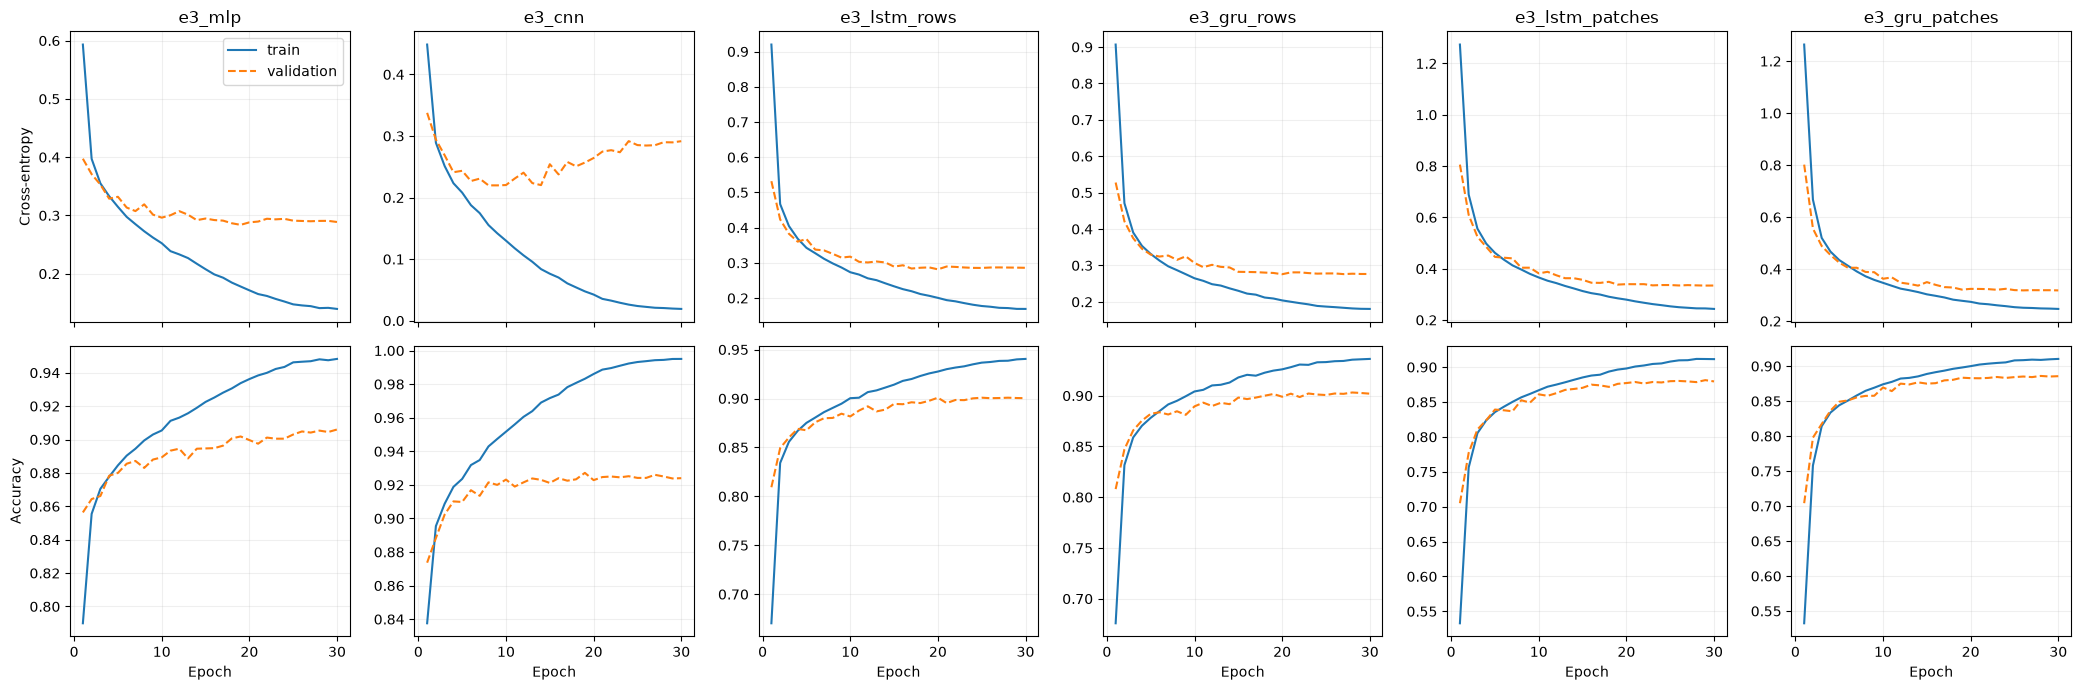

In [8]:
fig, axes = plt.subplots(2, 6, figsize=(21, 7), sharex=True)
for column, experiment in enumerate(EXPERIMENTS):
    history = pd.read_csv(RUN_DIR / experiment["id"] / "seed_42" / "history.csv")
    for split, style in [("train", "-"), ("validation", "--")]:
        axes[0, column].plot(history["epoch"], history[f"{split}_ce"], style, label=split)
        axes[1, column].plot(history["epoch"], history[f"{split}_accuracy"], style, label=split)
    axes[0, column].set_title(experiment["id"])
    axes[1, column].set_xlabel("Epoch")
    axes[0, column].grid(alpha=.2)
    axes[1, column].grid(alpha=.2)
axes[0, 0].set_ylabel("Cross-entropy")
axes[1, 0].set_ylabel("Accuracy")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "learning_curves_seed42.png", dpi=150)
plt.show()

## 6. Sequence-order diagnostics on validation images

All recurrent checkpoints are evaluated on the **same 256 validation images**, selected by their smallest original dataset indices. For each representation, we compare its original order, reversed order and one fixed permutation generated with seed 2026. These changes preserve token values but alter their positions. The weights remain fixed: this measures sensitivity to an order change at inference, not the performance of a model trained on that new order.

We also compute the mean per-image norm of the cross-entropy gradient with respect to each input token. A sum-reduced loss avoids scaling each image's gradient by batch size. The model is in evaluation mode, so dropout is disabled. On CUDA, cuDNN is disabled for this gradient calculation because its fused recurrent backward requires training mode. This input-sensitivity profile is **not a direct measurement of hidden-state gradients and does not prove vanishing gradients or long-term memory**. Sequences here contain only 28 or 49 steps.

mean       std
id              order                       
e3_gru_patches  original  0.878906  0.014084
                permuted  0.135417  0.044424
                reversed  0.175781  0.031250
e3_gru_rows     original  0.906250  0.011719
                permuted  0.416667  0.019269
                reversed  0.201823  0.016263
e3_lstm_patches original  0.873698  0.002255
                permuted  0.131510  0.016263
                reversed  0.180990  0.033222
e3_lstm_rows    original  0.907552  0.008132
                permuted  0.419271  0.041031
                reversed  0.256510  0.040658

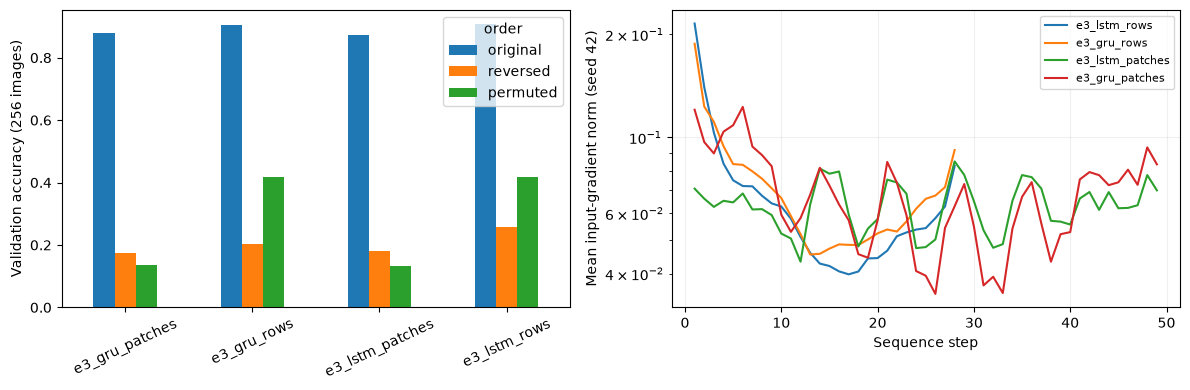

In [9]:
def load_best_model(experiment, seed):
    model = build_model(experiment).to(device)
    checkpoint = RUN_DIR / experiment["id"] / f"seed_{seed}" / "best.pt"
    model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
    return model.eval()


diagnostic_set = Subset(validation_set, range(256))
diagnostic_loader = make_loader(diagnostic_set)
np.save(RUN_DIR / "diagnostic_validation_indices.npy", validation_indices[:256])
order_rows, gradient_rows = [], []
for experiment in EXPERIMENTS:
    if experiment["model"] not in ("lstm", "gru"):
        continue
    steps = 28 if experiment["tokenizer"] == "rows" else 49
    permutation = torch.randperm(steps, generator=torch.Generator().manual_seed(SPLIT_SEED)).to(device)
    for seed in SEEDS:
        model = load_best_model(experiment, seed)
        correct = {"original": 0, "reversed": 0, "permuted": 0}
        total_gradient = torch.zeros(steps, dtype=torch.float64)
        count = 0
        for images, targets, _ in diagnostic_loader:
            images, targets = images.to(device), targets.to(device)
            sequence = image_sequence(images, experiment["tokenizer"]).detach()
            with torch.no_grad():
                for order, tokens in [("original", sequence), ("reversed", sequence.flip(1)),
                                      ("permuted", sequence[:, permutation])]:
                    predicted = model.forward_sequence(tokens).argmax(1)
                    correct[order] += (predicted == targets).sum().item()
            tokens = sequence.requires_grad_(True)
            backend = torch.backends.cudnn.flags(enabled=False) if device.type == "cuda" else nullcontext()
            with backend:
                loss = F.cross_entropy(model.forward_sequence(tokens), targets, reduction="sum")
                gradient, = torch.autograd.grad(loss, tokens)
            total_gradient += gradient.detach().norm(dim=2).sum(dim=0).cpu().double()
            count += targets.numel()
        for order, n_correct in correct.items():
            order_rows.append({**experiment, "seed": seed, "split": "validation", "n_samples": count,
                               "order": order, "accuracy": n_correct / count})
        for step, value in enumerate(total_gradient / count, start=1):
            gradient_rows.append({**experiment, "seed": seed, "step": step,
                                  "mean_input_gradient_norm": value.item()})
        del model
order_results = pd.DataFrame(order_rows)
gradient_results = pd.DataFrame(gradient_rows)
order_results.to_csv(RUN_DIR / "sequence_order_diagnostics.csv", index=False)
gradient_results.to_csv(RUN_DIR / "input_gradient_diagnostics.csv", index=False)
display(order_results.groupby(["id", "order"])["accuracy"].agg(["mean", "std"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order_summary = order_results.groupby(["id", "order"])["accuracy"].mean().unstack()
order_summary[["original", "reversed", "permuted"]].plot.bar(ax=axes[0], rot=25)
axes[0].set_ylabel("Validation accuracy (256 images)")
axes[0].set_xlabel("")
for experiment in EXPERIMENTS:
    if experiment["model"] in ("lstm", "gru"):
        profile = gradient_results[(gradient_results["id"] == experiment["id"]) &
                                   (gradient_results["seed"] == 42)]
        axes[1].semilogy(profile["step"], profile["mean_input_gradient_norm"].clip(lower=1e-15),
                         label=experiment["id"])
axes[1].set(xlabel="Sequence step", ylabel="Mean input-gradient norm (seed 42)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "sequence_diagnostics.png", dpi=150)
plt.show()

## 7. Frozen protocol and held-out test evaluation

The configurations, seeds, epoch budget, preprocessing and validation-selected checkpoints are now fixed. Running the next cell explicitly confirms held-out test evaluation of these checkpoints after all 18 training runs. No model selection uses the resulting test scores.

Accuracy is the fraction of correct predictions. Macro-F1 is the unweighted mean of ten per-class F1 scores, so each class contributes equally. The following cells save every prediction, confusion matrix and per-class metric for each run. Only these newly measured results are used in the comparison.

In [10]:
assert len(training_rows) == len(EXPERIMENTS) * len(SEEDS) == 18
assert all(len(pd.read_csv(RUN_DIR / row["id"] / f"seed_{row['seed']}" / "history.csv")) == EPOCHS
           for row in training_rows)
settings["protocol_frozen_before_test"] = True
settings["test_evaluation_confirmed_utc"] = datetime.now(timezone.utc).isoformat()
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
base_test = FashionMNIST(str(DATA_DIR), train=False, download=True)
assert len(base_test) == 10000
test_set = NormalizedImages(base_test.data, base_test.targets, np.arange(len(base_test)))
test_loader = make_loader(test_set)


results = []
for row in training_rows:
    model = load_best_model(row, row["seed"])
    test_ce, test_accuracy, predictions = evaluate(model, test_loader, collect_predictions=True)
    frame = pd.DataFrame(predictions, columns=["index", "target", "prediction", "confidence"])
    assert len(frame) == 10000
    confusion = confusion_matrix(frame["target"], frame["prediction"], labels=np.arange(10))
    metrics = classification_report(frame["target"], frame["prediction"], labels=np.arange(10),
                                    target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    per_class = pd.DataFrame([{"class": name, **metrics[name]} for name in CLASS_NAMES])
    per_class = per_class.rename(columns={"f1-score": "f1"})
    macro_f1 = metrics["macro avg"]["f1-score"]
    directory = RUN_DIR / row["id"] / f"seed_{row['seed']}"
    frame.to_csv(directory / "test_predictions.csv", index=False)
    pd.DataFrame(confusion, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(directory / "test_confusion.csv")
    per_class.to_csv(directory / "test_per_class.csv", index=False)
    results.append({**row, "test_accuracy": test_accuracy, "test_macro_f1": macro_f1, "test_ce": test_ce})
    del model
results = pd.DataFrame(results)
result_columns = ["id", "model", "tokenizer", "seed", "val_accuracy", "test_accuracy", "test_macro_f1",
                  "n_parameters", "train_seconds", "seconds_per_epoch", "peak_memory_mib", "best_epoch", "test_ce"]
results = results[result_columns]
results.to_csv(RUN_DIR / "results.csv", index=False)
display(results)

,id,model,tokenizer,seed,val_accuracy,test_accuracy,test_macro_f1,n_parameters,train_seconds,seconds_per_epoch,peak_memory_mib,best_epoch,test_ce
0,e3_mlp,mlp,none,42,0.906000,0.8995,0.899303,235146,26.208774,0.858143,22.515137,30,0.317295
1,e3_mlp,mlp,none,43,0.907167,0.9009,0.900719,235146,25.657690,0.845489,22.515137,28,0.308929
2,e3_mlp,mlp,none,44,0.902833,0.9001,0.899921,235146,25.106790,0.832258,22.515137,30,0.318294
3,e3_cnn,cnn,none,42,0.927167,0.9217,0.921528,421738,28.913506,0.956978,165.121582,19,0.284409
4,e3_cnn,cnn,none,43,0.931167,0.9258,0.925491,421738,29.067362,0.966113,165.121582,25,0.310209
5,e3_cnn,cnn,none,44,0.931000,0.9269,0.926808,421738,29.003199,0.964884,165.121582,29,0.324966
6,e3_lstm_rows,lstm,rows,42,0.900833,0.8953,0.894738,82186,27.617286,0.918771,134.006836,20,0.301851
7,e3_lstm_rows,lstm,rows,43,0.900000,0.8936,0.893319,82186,27.393230,0.914241,134.006836,19,0.299835
8,e3_lstm_rows,lstm,rows,44,0.899500,0.8921,0.891699,82186,27.351205,0.909826,134.006836,23,0.311250
9,e3_gru_rows,gru,rows,42,0.903167,0.9009,0.900616,61962,26.768991,0.885706,127.400391,28,0.288763


## 8. Comparison, confusion matrices and classification errors

The summary uses the mean and sample standard deviation across the three seeds. Accuracy and macro-F1 are stored as fractions. Learning curves, confusion matrices and error galleries use the preselected seed 42 for all models. Errors are sorted by confidence to inspect confidently wrong predictions; this selection is not a representative sample of all test images.

,id,model,tokenizer,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,n_parameters,train_seconds_mean,seconds_per_epoch_mean
0,e3_mlp,mlp,none,0.900167,0.000702,0.899981,0.000709,235146,25.657751,0.845296
1,e3_cnn,cnn,none,0.924800,0.002740,0.924609,0.002748,421738,28.994689,0.962658
2,e3_lstm_rows,lstm,rows,0.893667,0.001601,0.893252,0.001521,82186,27.453907,0.914279
3,e3_gru_rows,gru,rows,0.901733,0.001193,0.901537,0.001329,61962,26.617906,0.882669
4,e3_lstm_patches,lstm,patches,0.877633,0.000666,0.877482,0.000749,76042,35.222014,1.172496
5,e3_gru_patches,gru,patches,0.881867,0.003219,0.881736,0.003261,57354,33.826771,1.126122


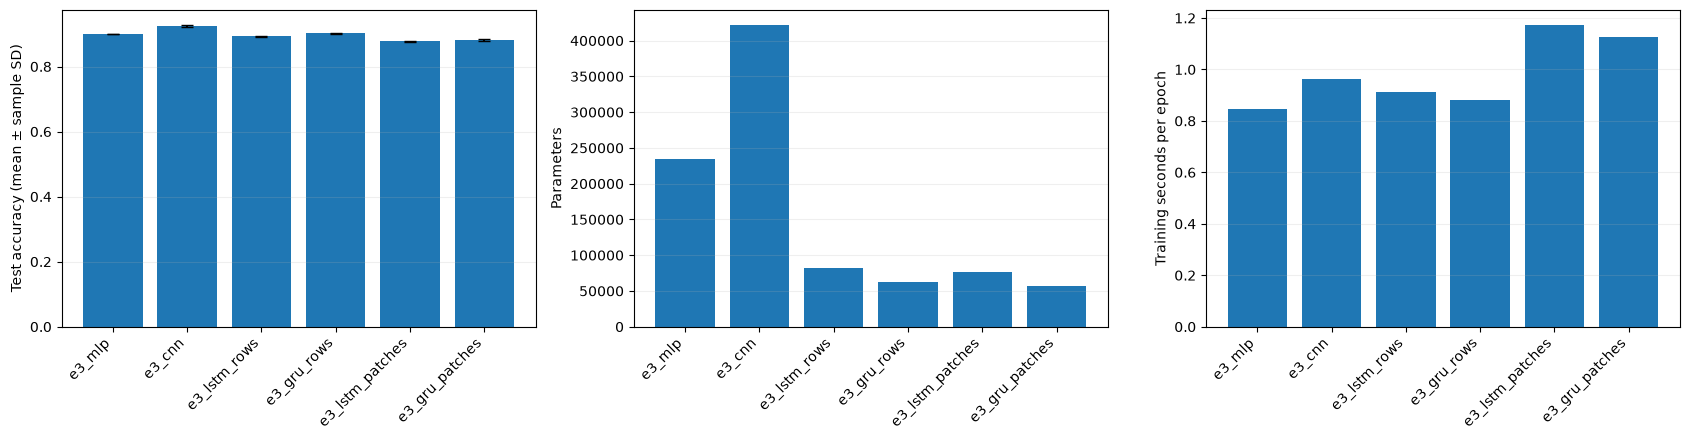

In [11]:
summary = results.groupby(["id", "model", "tokenizer"], sort=False).agg(
    test_accuracy_mean=("test_accuracy", "mean"), test_accuracy_std=("test_accuracy", "std"),
    test_macro_f1_mean=("test_macro_f1", "mean"), test_macro_f1_std=("test_macro_f1", "std"),
    n_parameters=("n_parameters", "first"), train_seconds_mean=("train_seconds", "mean"),
    seconds_per_epoch_mean=("seconds_per_epoch", "mean"),
).reset_index()
summary.to_csv(RUN_DIR / "summary.csv", index=False)
display(summary)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.arange(len(summary))
axes[0].bar(x, summary["test_accuracy_mean"], yerr=summary["test_accuracy_std"], capsize=4)
axes[0].set_ylabel("Test accuracy (mean ± sample SD)")
axes[1].bar(x, summary["n_parameters"])
axes[1].set_ylabel("Parameters")
axes[2].bar(x, summary["seconds_per_epoch_mean"])
axes[2].set_ylabel("Training seconds per epoch")
for ax in axes:
    ax.set_xticks(x, summary["id"], rotation=45, ha="right")
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "model_comparison.png", dpi=150)
plt.show()

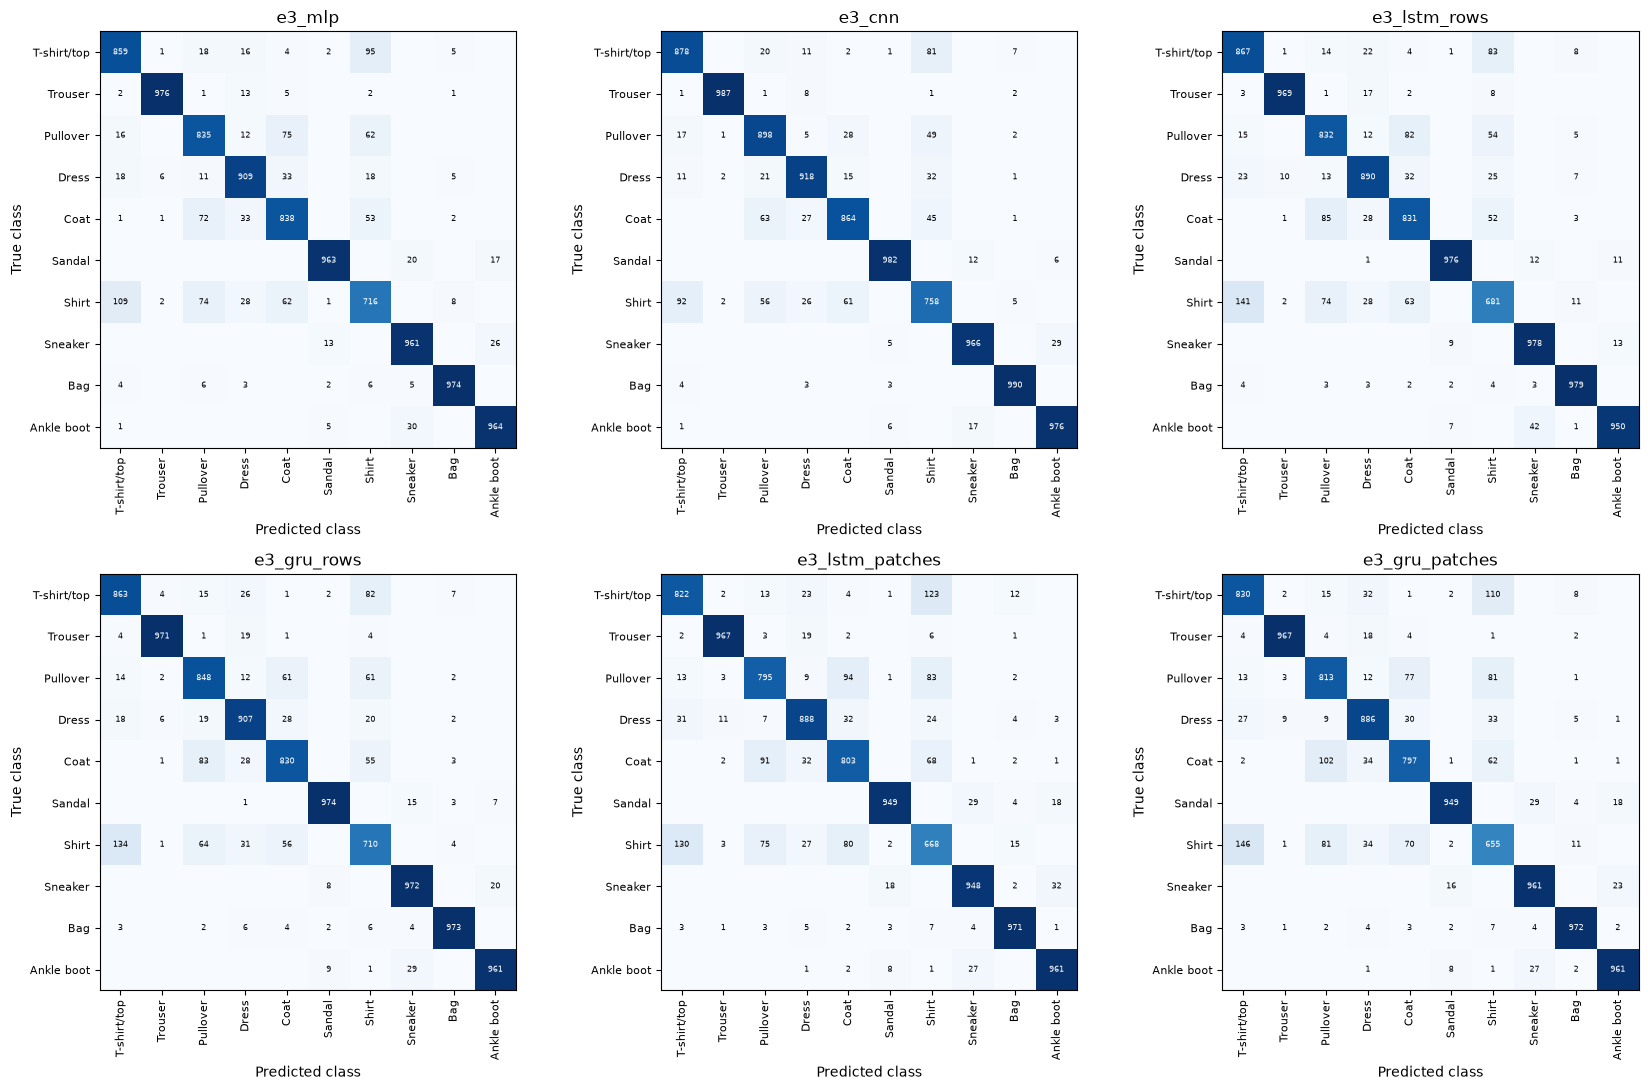

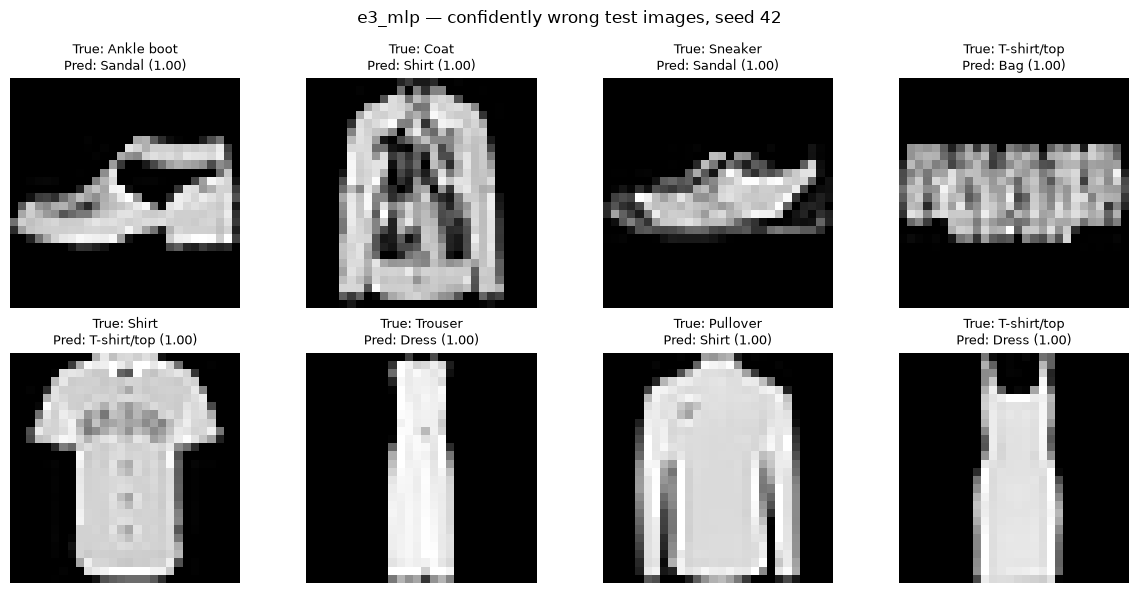

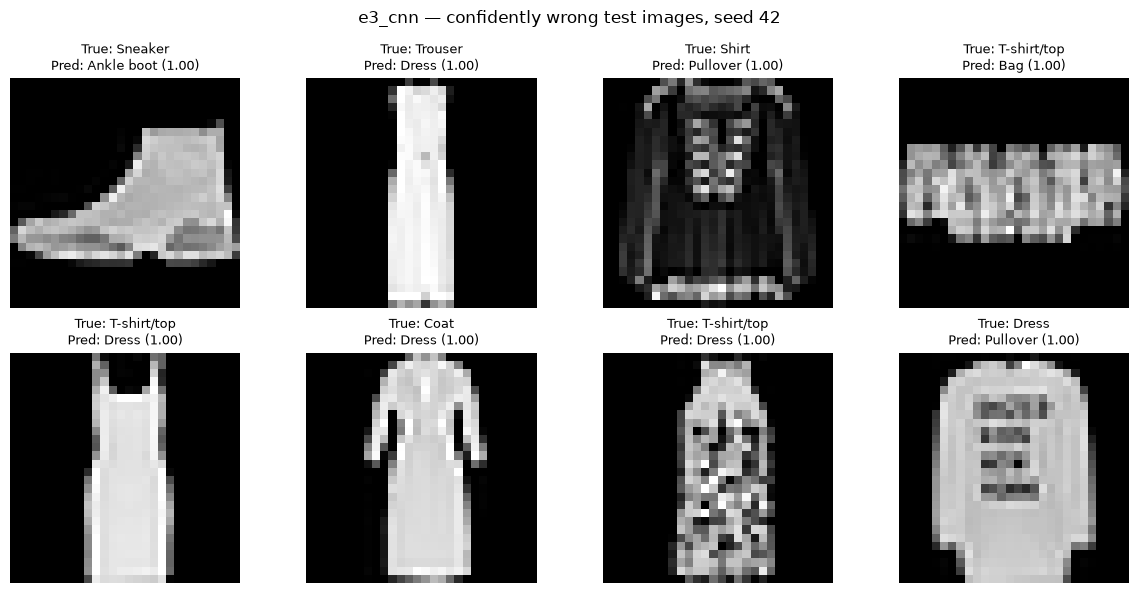

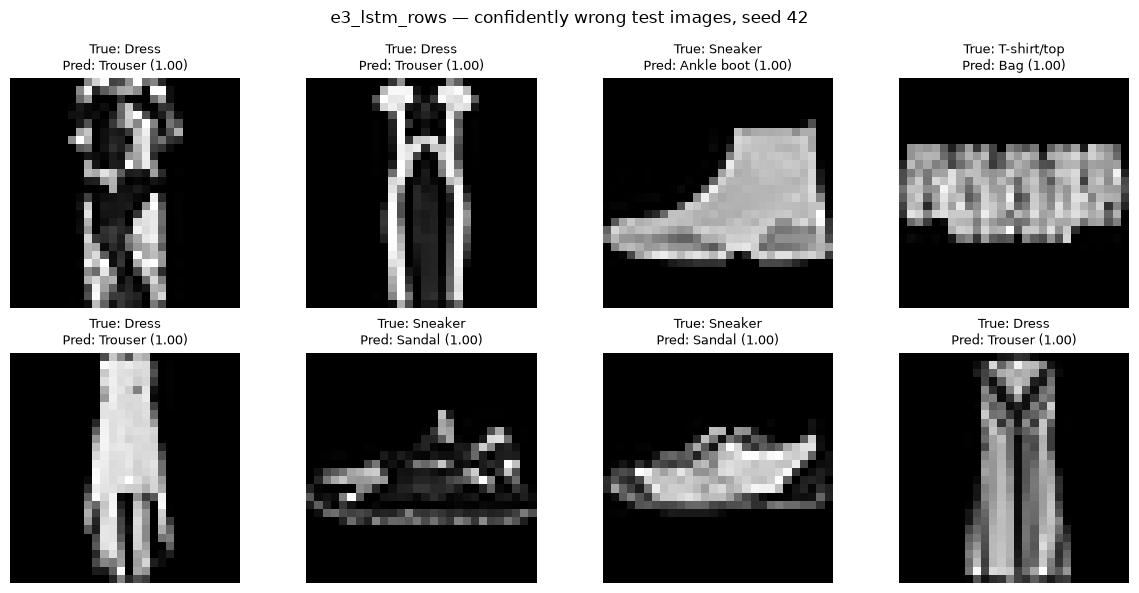

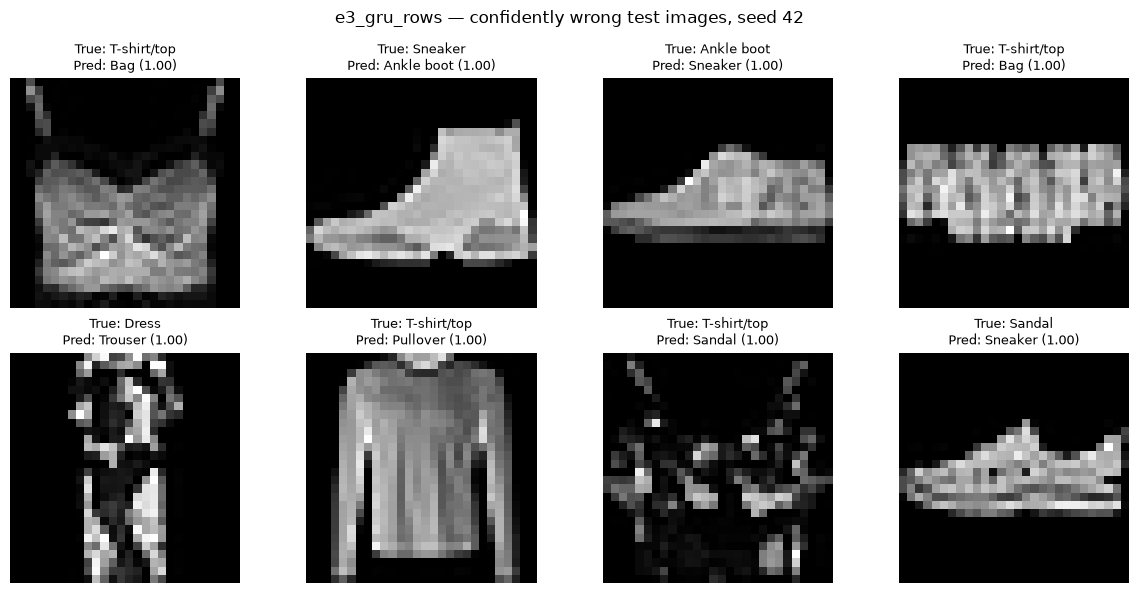

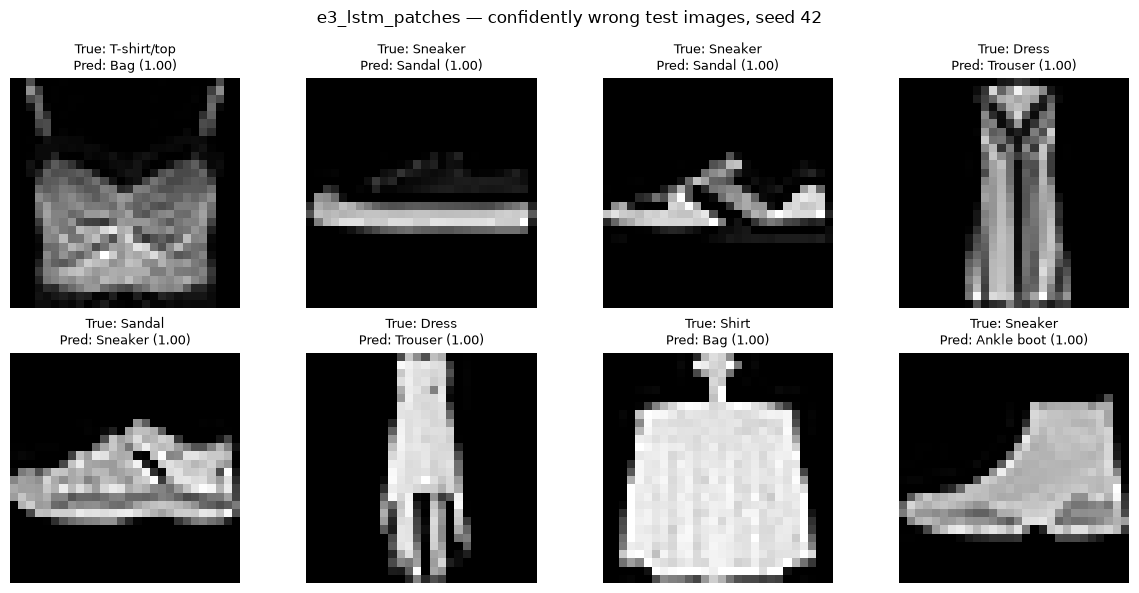

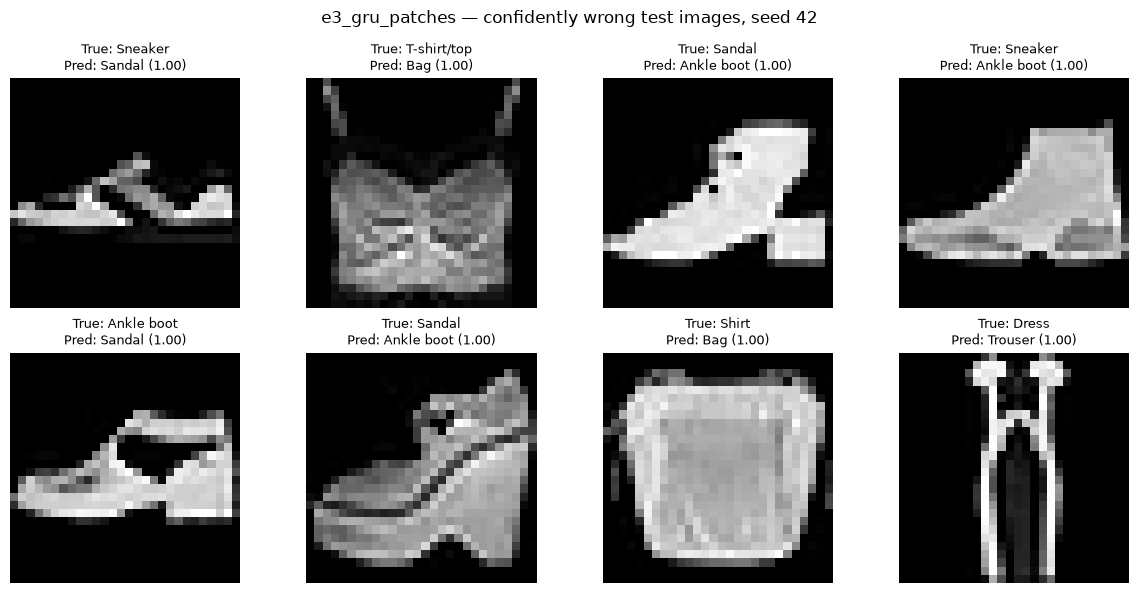

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
for experiment, ax in zip(EXPERIMENTS, axes.flat):
    directory = RUN_DIR / experiment["id"] / "seed_42"
    confusion = pd.read_csv(directory / "test_confusion.csv", index_col=0).to_numpy()
    ax.imshow(confusion, cmap="Blues")
    ax.set_title(experiment["id"])
    ax.set_xticks(range(10), CLASS_NAMES, rotation=90, fontsize=8)
    ax.set_yticks(range(10), CLASS_NAMES, fontsize=8)
    ax.set(xlabel="Predicted class", ylabel="True class")
    for i in range(10):
        for j in range(10):
            if confusion[i, j]:
                ax.text(j, i, str(confusion[i, j]), ha="center", va="center", fontsize=6,
                        color="white" if confusion[i, j] > confusion.max() / 2 else "black")
fig.tight_layout()
fig.savefig(RUN_DIR / "confusion_matrices_seed42.png", dpi=150)
plt.show()

for experiment in EXPERIMENTS:
    directory = RUN_DIR / experiment["id"] / "seed_42"
    predictions = pd.read_csv(directory / "test_predictions.csv")
    errors = predictions[predictions["target"] != predictions["prediction"]]
    errors = errors.sort_values("confidence", ascending=False).head(8)
    if errors.empty:
        print(f"{experiment['id']}: no test errors.")
        continue
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax in axes.flat:
        ax.axis("off")
    for ax, error in zip(axes.flat, errors.itertuples()):
        ax.imshow(base_test.data[int(error.index)], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"True: {CLASS_NAMES[int(error.target)]}\n"
                     f"Pred: {CLASS_NAMES[int(error.prediction)]} ({error.confidence:.2f})", fontsize=9)
    fig.suptitle(f"{experiment['id']} — confidently wrong test images, seed 42")
    fig.tight_layout()
    fig.savefig(directory / "test_errors.png", dpi=150)
    plt.show()

## 9. Findings

GRU with row tokens reaches 90.17% mean test accuracy, compared with 89.37% for LSTM. The independently trained MLP and CNN reach 90.02% and 92.48%. Row tokens outperform patch tokens by 1.60 percentage points for LSTM and 1.99 points for GRU. Patches change both sequence length and input dimension, so this comparison does not isolate memory length.

On the fixed 256-image validation subset, LSTM-row accuracy averages 90.76% in the original order, 25.65% after reversal and 41.93% after permutation. This drop shows dependence on the learned scan order. The reordered inputs differ from the training distribution; the test does not establish how the models would perform if trained with a different order. Input-gradient profiles describe local sensitivity to the original tokens.